# Fase 3 · Modelos de referencia

Antes de pasar a machine learning necesitamos saber **cuánto aciertan los métodos clásicos de series
temporales**. Es el listón que LightGBM tendrá que batir en la fase 4.

1. Cómo se evalúa: validación de origen móvil
2. Los modelos
3. Resultados en dos periodos
4. Error según el horizonte
5. Sesgo: ¿se quedan cortos o se pasan?
6. Semana Santa
7. Intervalos de predicción
8. Ejemplo: una previsión real frente a lo que pasó
9. Previsión de octubre de 2026 a septiembre de 2027
10. Conclusiones

El código de los modelos está en `src/modelos_base.py` y el de la evaluación en `src/backtest.py`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

from backtest import CALENDARIO, backtest, cargar_dataset, mape_por_horizonte, metricas
from descarga import calendario
from modelos_base import MODELOS, combinacion

FIG = RAIZ / "outputs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
AZUL, NARANJA, AQUA, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b"
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0", "axes.grid": True,
    "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "lines.linewidth": 2, "legend.frameon": False, "font.size": 10.5,
})
miles = mticker.FuncFormatter(lambda x, _: (f"{x/1e6:g} M" if x >= 1e6 else f"{x/1e3:.0f} k").replace(".", ","))

def guardar(nombre):
    plt.savefig(FIG / f"{nombre}.png", bbox_inches="tight")
    plt.show()

OBJ = "costa_blanca_pernoctaciones_total"
d = cargar_dataset()
print(f"Datos: {d.index.min():%Y-%m} → {d[OBJ].last_valid_index():%Y-%m}")

Datos: 1999-01 → 2026-09


## 1. Cómo se evalúa: validación de origen móvil

Simulamos que usamos cada modelo de verdad, mes a mes:

- En cada mes **origen** T, el modelo se entrena **solo con los datos que existían en T**.
- Predice los 12 meses siguientes (T+1 … T+12).
- Se compara con lo que pasó, se avanza un mes y se repite.

Así ningún modelo "ve el futuro", y medimos el error a 1, 2 … 12 meses vista.

Usamos **dos periodos de evaluación**, porque uno solo puede engañar:

| Periodo | Meses evaluados | Por qué |
|---|---|---|
| 2015–2019 | enero 2015 – diciembre 2019 | Antes del COVID; incluye el salto de 2015–2017 y varios cambios de mes de la Semana Santa |
| 2023–2026 | abril 2023 – septiembre 2026 | Después del COVID; empieza en abril de 2023 para que "hace un año" ya no sea COVID |

**Métrica principal:** MAPE, el error absoluto medio en porcentaje. También el sesgo (si el modelo se
queda corto o se pasa de media) y la cobertura de los intervalos.

## 2. Los modelos

| Modelo | Qué hace | COVID |
|---|---|---|
| **Ingenuo estacional** | "Igual que el mismo mes del año pasado" | No le afecta en estos periodos |
| **Ingenuo + tendencia** | Lo anterior × el crecimiento interanual de los últimos 3 meses | Sin ajuste si esos meses son COVID |
| **ETS** (Holt-Winters) | Nivel + tendencia amortiguada + estacionalidad, en logaritmos | Meses COVID sustituidos por el mismo mes de 2019 |
| **SARIMA** (1,0,0)(1,1,1)₁₂ | Diferencia estacional + memoria de corto plazo, en logaritmos. Orden elegido por AIC sobre 2003–2019 | Meses COVID como desconocidos: el modelo los salta |
| **SARIMAX + Semana Santa** | SARIMA + los días de Semana Santa de cada mes | Igual que SARIMA |
| **Combinación** | Media geométrica de ETS y SARIMAX | — |

Combinar modelos es una técnica clásica de previsión: los errores de modelos distintos se compensan
en parte, y la combinación suele ser más estable que cualquiera de sus componentes.

## 3. Resultados en dos periodos

El backtesting completo tarda unos 4 minutos. El resultado se guarda en `outputs/backtest_fase3.csv`;
si ya existe, se carga en lugar de recalcularlo (cambia `RECALCULAR` a `True` para repetirlo).

In [2]:
RECALCULAR = False
CACHE = RAIZ / "outputs" / "backtest_fase3.csv"
PERIODOS = {"2015–2019": ("2015-01-01", "2019-12-01"), "2023–2026": ("2023-04-01", None)}

if CACHE.exists() and not RECALCULAR:
    res = pd.read_csv(CACHE, parse_dates=["fecha", "origen"])
else:
    partes = []
    for periodo, (desde, hasta) in PERIODOS.items():
        for nombre, f in MODELOS.items():
            partes.append(backtest(d, f, OBJ, eval_desde=desde, eval_hasta=hasta, nombre=nombre).assign(periodo=periodo))
    res = pd.concat(partes, ignore_index=True)
    res.to_csv(CACHE, index=False)

orden = list(MODELOS)
tabla = metricas(res, ["periodo", "modelo"])
mape = tabla["MAPE"].unstack(0).loc[orden]
mape["Media"] = mape.mean(axis=1)
mape.round(2)

periodo,2015–2019,2023–2026,Media
modelo,,,
Ingenuo estacional,4.74,4.50,4.62
Ingenuo + tendencia,5.45,5.09,5.27
ETS,4.62,3.61,4.11
SARIMA,5.28,3.34,4.31
SARIMAX + Semana Santa,4.61,3.61,4.11
Combinación ETS + SARIMAX,4.24,3.48,3.86


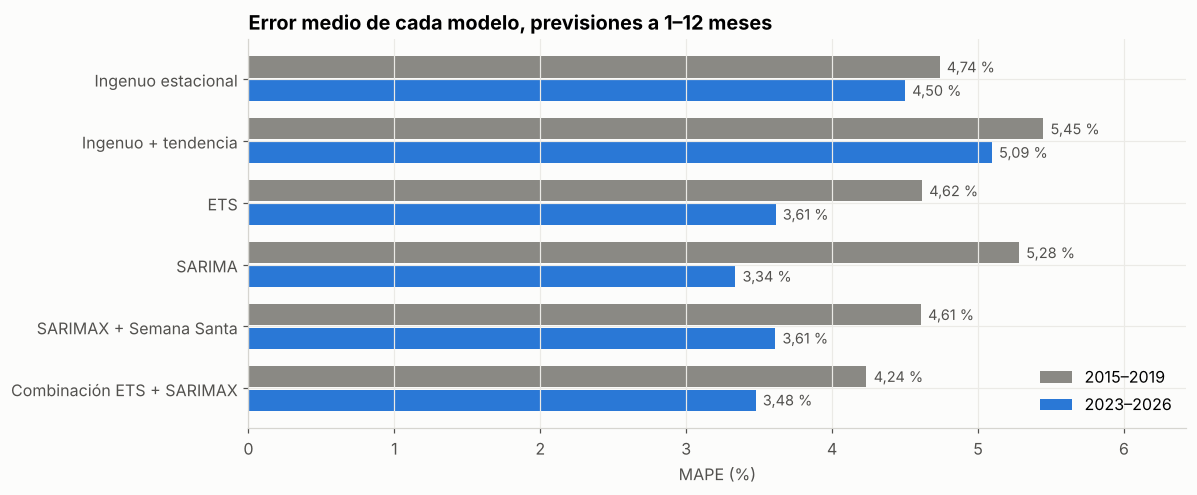

Mejora de la combinación sobre el ingenuo estacional: {'2015–2019': 11.0, '2023–2026': 23.0, 'Media': 17.0}


In [3]:
fig, ax = plt.subplots(figsize=(11, 4.6))
y_pos = np.arange(len(orden))
alto = 0.38
for i, (periodo, col) in enumerate(zip(["2015–2019", "2023–2026"], [GRIS, AZUL])):
    v = mape.loc[orden, periodo]
    ax.barh(y_pos + (i - 0.5) * alto, v, height=alto - 0.04, color=col, label=periodo)
    for yy, val in zip(y_pos + (i - 0.5) * alto, v):
        ax.text(val + 0.05, yy, f"{val:.2f} %".replace(".", ","), va="center", fontsize=9.5, color="#52514e")
ax.set_yticks(y_pos, orden)
ax.invert_yaxis()
ax.set_xlabel("MAPE (%)")
ax.set_xlim(0, mape[["2015–2019", "2023–2026"]].max().max() * 1.18)
ax.set_title("Error medio de cada modelo, previsiones a 1–12 meses")
ax.legend(loc="lower right")
guardar("11_mape_modelos_base")

ref = mape.loc["Ingenuo estacional"]
mejora = (1 - mape.loc["Combinación ETS + SARIMAX"] / ref) * 100
print("Mejora de la combinación sobre el ingenuo estacional:", mejora.round(0).to_dict())

**Lectura:**
- **Ningún modelo gana en los dos periodos.** SARIMA es el mejor en 2023–2026 (3,34 %), pero en
  2015–2019 es peor que el ingenuo (5,28 % frente a 4,74 %): no supo seguir el salto de 2015–2017.
- **La combinación ETS + SARIMAX es la más robusta:** la mejor en 2015–2019 (4,24 %) y la segunda en
  2023–2026 (3,48 %). Mejora al ingenuo estacional en un 11 % y un 23 % según el periodo.
- **Añadir tendencia al ingenuo empeora:** el crecimiento de los últimos 3 meses es ruidoso y no se
  mantiene. Ojo con esto en la fase 4: las variables de "momento reciente" pueden sobrerreaccionar.

**Modelo de referencia elegido para la fase 4:** la combinación ETS + SARIMAX.

## 4. Error según el horizonte

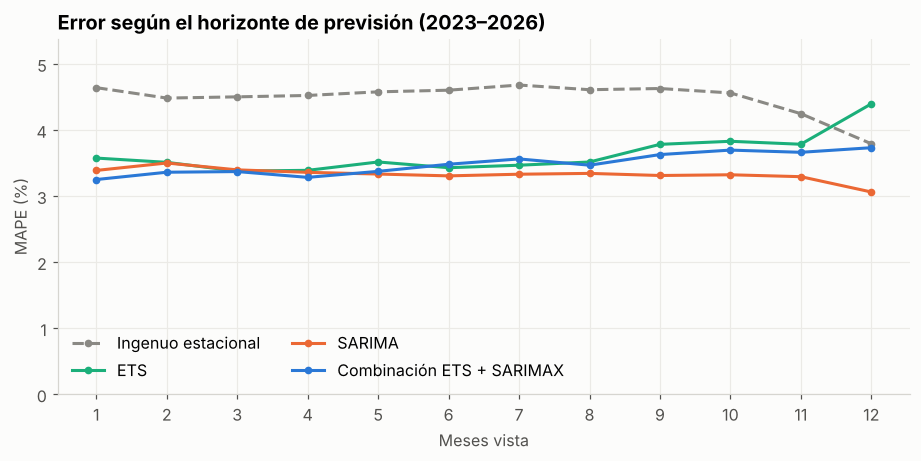

modelo,Ingenuo estacional,Ingenuo + tendencia,ETS,SARIMA,SARIMAX + Semana Santa,Combinación ETS + SARIMAX
h,,,,,,
1,4.64,4.58,3.58,3.39,3.49,3.25
3,4.50,4.79,3.38,3.40,3.63,3.37
6,4.60,5.07,3.43,3.31,3.65,3.48
12,3.79,5.24,4.40,3.06,3.29,3.73


In [4]:
h = mape_por_horizonte(res[res.periodo == "2023–2026"])[orden]
fig, ax = plt.subplots(figsize=(10, 4.2))
estilos = {"Ingenuo estacional": (GRIS, "--"), "ETS": (AQUA, "-"), "SARIMA": (NARANJA, "-"),
           "Combinación ETS + SARIMAX": (AZUL, "-")}
for m, (col, ls) in estilos.items():
    ax.plot(h.index, h[m], color=col, ls=ls, marker="o", ms=4, label=m)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Meses vista"); ax.set_ylabel("MAPE (%)")
ax.set_ylim(0, h[list(estilos)].max().max() * 1.15)
ax.set_title("Error según el horizonte de previsión (2023–2026)")
ax.legend(ncol=2, loc="lower left")
guardar("12_error_horizonte")
h.loc[[1, 3, 6, 12]].round(2)

**Lectura:** el error apenas crece con el horizonte. La combinación pasa del 3,25 % a 1 mes vista al
3,73 % a 12 meses, y SARIMA incluso mejora a 12 meses. Es lo esperable en una serie tan estacional:
casi toda la información está en el patrón anual, y saber el último mes aporta poco.

Esto anticipa algo para la fase 4: la ganancia de ML vendrá de **mejorar la estimación del nivel y del
crecimiento**, no de aprovechar mejor los últimos meses.

## 5. Sesgo: ¿se quedan cortos o se pasan?

In [5]:
sesgo = (res.assign(año=res.fecha.dt.year)
           .pivot_table(index=["periodo", "año"], columns="modelo", values="error_pct")[orden])
sesgo.round(1)

modelo          Ingenuo estacional  Ingenuo + tendencia  ETS  SARIMA  \
periodo   año                                                          
2015–2019 2015                -3.7                  0.1 -1.3    -3.8   
          2016                -7.8                 -2.5 -5.2    -8.9   
          2017                -0.9                  4.7 -0.4    -5.2   
          2018                 0.4                  0.7  0.5    -2.8   
          2019                 1.0                  1.5  1.8    -0.5   
2023–2026 2023                -2.0                 -1.1 -3.2     0.8   
          2024                -7.4                 -2.4 -4.4    -3.8   
          2025                -0.7                  3.3 -0.8    -1.4   
          2026                -1.5                 -0.1 -0.6    -1.4   

modelo          SARIMAX + Semana Santa  Combinación ETS + SARIMAX  
periodo   año                                                      
2015–2019 2015                    -3.1                       -2.2  
          2016                    -7.8                       -6.5  
          2017                    -3.3                       -1.9  
          2018                    -1.8                       -0.6  
          2019                     0.1                        0.9  
2023–2026 2023                     0.1                       -1.6  
          2024                    -4.5                       -4.4  
          2025                    -0.9                       -0.9  
          2026                    -1.2                       -0.9

**Lectura:** todos los modelos se quedan cortos casi siempre (sesgo negativo), sobre todo en los años
de crecimiento fuerte: **2016** (entre −5 % y −9 %) y **2024** (entre −4 % y −7 %), salvo el ingenuo
con tendencia, que se queda en −2,5 %. Los modelos aprenden un crecimiento medio y tardan en reaccionar cuando la demanda acelera.

Es el principal margen de mejora para la fase 4: variables que anticipen las aceleraciones, como el
crecimiento interanual reciente (bien suavizado) o los pasajeros del aeropuerto.

## 6. Semana Santa

Error en marzo y abril en el periodo 2015–2019, que tiene varios cambios de mes de la Semana Santa
(2016 en marzo; 2015, 2017 y 2019 en abril; 2018 a caballo).

In [6]:
pre = res[(res.periodo == "2015–2019") & res.fecha.dt.month.isin([3, 4])]
ss = pre.assign(ape=pre.error_pct.abs()).groupby("modelo").ape.mean().loc[orden]
resto = res[(res.periodo == "2015–2019") & ~res.fecha.dt.month.isin([3, 4])]
otros = resto.assign(ape=resto.error_pct.abs()).groupby("modelo").ape.mean().loc[orden]
pd.DataFrame({"MAPE marzo y abril": ss, "MAPE resto de meses": otros}).round(2)

,MAPE marzo y abril,MAPE resto de meses
modelo,,
Ingenuo estacional,6.74,4.36
Ingenuo + tendencia,7.39,5.08
ETS,4.56,4.63
SARIMA,5.33,5.27
SARIMAX + Semana Santa,4.95,4.54
Combinación ETS + SARIMAX,3.80,4.32


**Lectura:** en marzo y abril de 2015–2019 el ingenuo falla un 6,7 % y SARIMA un 5,3 %. Añadir los
días de Semana Santa baja SARIMAX al 4,95 %, y la combinación al 3,8 %.

En 2023–2026, en cambio, la variable no ayuda: en ese periodo solo hay un cambio de mes (2024), poco
para estimar bien el efecto. Por eso conviene evaluar siempre en más de un periodo.

## 7. Intervalos de predicción

In [7]:
cob = tabla["cobertura"].unstack(0).loc[["SARIMA", "SARIMAX + Semana Santa", "Combinación ETS + SARIMAX"]]
cob.round(1)

periodo,2015–2019,2023–2026
modelo,,
SARIMA,77.8,91.8
SARIMAX + Semana Santa,79.1,91.6
Combinación ETS + SARIMAX,81.0,90.4


Los intervalos son del **80 %**: si están bien calibrados, el valor real debería caer dentro en 8 de
cada 10 casos.

**Lectura:** en 2015–2019 la cobertura es casi perfecta (78–81 %). En 2023–2026 es del 90–92 %: los
intervalos son **demasiado anchos**. Tiene sentido: el modelo estima su incertidumbre con toda la
historia, incluidos los saltos alrededor del COVID, y desde 2023 la serie ha sido más tranquila. Es
preferible a intervalos estrechos que fallen, pero en la fase 4 conviene recalibrarlos.

## 8. Ejemplo: una previsión real frente a lo que pasó

Previsión hecha con los datos hasta **septiembre de 2025** para los 12 meses siguientes, comparada con
los datos reales.

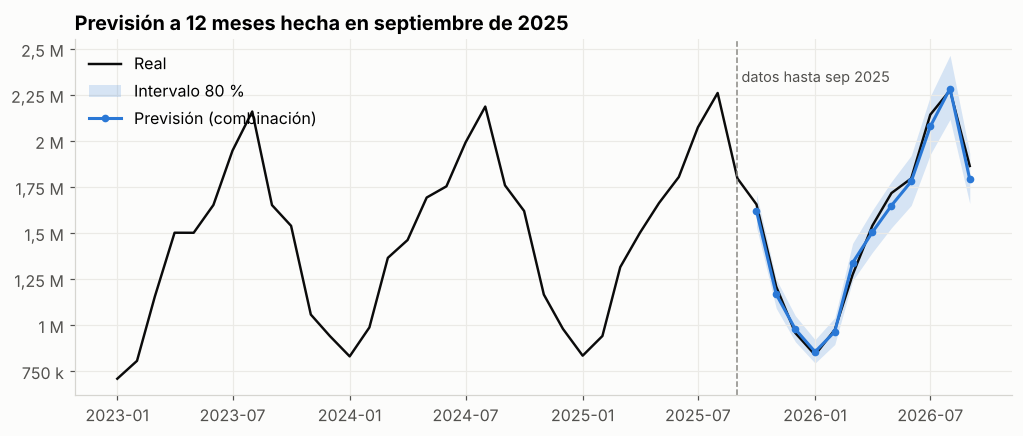

MAPE de esta previsión: 2.52 % · meses dentro del intervalo: 12 de 12


In [8]:
T = pd.Timestamp("2025-09-01")
ej = res[(res.modelo == "Combinación ETS + SARIMAX") & (res.origen == T)].set_index("fecha")
hist = d.loc["2023-01":"2026-09", OBJ]

fig, ax = plt.subplots()
ax.plot(hist.index, hist, color=TINTA, lw=1.6, label="Real")
ax.fill_between(ej.index, ej["inf"], ej["sup"], color=AZUL, alpha=0.18, lw=0, label="Intervalo 80 %")
ax.plot(ej.index, ej.pred, color=AZUL, marker="o", ms=4, label="Previsión (combinación)")
ax.axvline(T, color=GRIS, lw=1, ls="--")
ax.text(T, hist.max() * 1.02, " datos hasta sep 2025", color="#52514e", fontsize=9.5)
ax.yaxis.set_major_formatter(miles)
ax.set_title("Previsión a 12 meses hecha en septiembre de 2025")
ax.legend(loc="upper left")
guardar("13_ejemplo_prevision")
print(f"MAPE de esta previsión: {ej.error_pct.abs().mean():.2f} % · meses dentro del intervalo: "
      f"{((ej.real >= ej['inf']) & (ej.real <= ej['sup'])).sum()} de {len(ej)}")

## 9. Previsión de octubre de 2026 a septiembre de 2027

Con todos los datos disponibles (hasta septiembre de 2026), la combinación prevé los 12 meses
siguientes. El calendario futuro (Semana Santa de 2027: 28 de marzo) se calcula con
`descarga.calendario`.

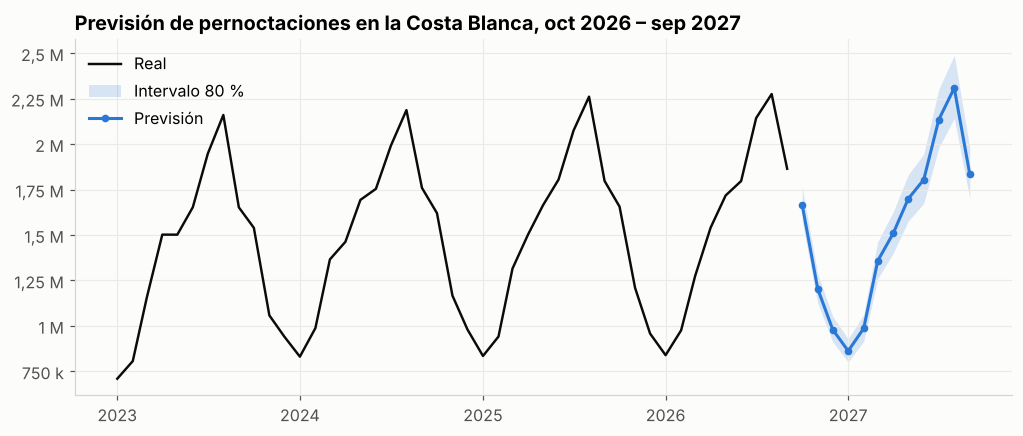

Total previsto: 18.35 M · 12 meses anteriores: 18.25 M


,pred,inf,sup,año_anterior,variación %
oct 2026,1666,1577,1761,1656,0.6
nov 2026,1204,1127,1288,1209,-0.4
dic 2026,980,912,1052,958,2.3
ene 2027,862,801,928,839,2.8
feb 2027,986,916,1062,975,1.1
mar 2027,1358,1260,1463,1274,6.5
abr 2027,1509,1401,1627,1540,-2.0
may 2027,1699,1577,1832,1717,-1.1
jun 2027,1804,1674,1945,1797,0.4
jul 2027,2135,1980,2301,2143,-0.4


In [9]:
T = d[OBJ].last_valid_index()
futuro = calendario((T + pd.DateOffset(months=1)).strftime("%Y-%m-%d"),
                    (T + pd.DateOffset(months=12)).strftime("%Y-%m-%d")).set_index("fecha")
futuro["covid"] = 0
prev = combinacion(d, futuro[[c for c in CALENDARIO if c in futuro]], OBJ)
prev["año_anterior"] = [d.at[f - pd.DateOffset(months=12), OBJ] for f in prev.index]
prev["variacion_pct"] = (prev.pred / prev.año_anterior - 1) * 100
prev.to_csv(RAIZ / "outputs" / "prevision_2026_2027.csv")

hist = d.loc["2023-01":, OBJ]
fig, ax = plt.subplots()
ax.plot(hist.index, hist, color=TINTA, lw=1.6, label="Real")
ax.fill_between(prev.index, prev["inf"], prev["sup"], color=AZUL, alpha=0.18, lw=0, label="Intervalo 80 %")
ax.plot(prev.index, prev.pred, color=AZUL, marker="o", ms=4, label="Previsión")
ax.yaxis.set_major_formatter(miles)
ax.set_title("Previsión de pernoctaciones en la Costa Blanca, oct 2026 – sep 2027")
ax.legend(loc="upper left")
guardar("14_prevision_2026_2027")

tabla_prev = (prev[["pred", "inf", "sup", "año_anterior"]] / 1e3).round(0).astype(int)
tabla_prev["variación %"] = prev.variacion_pct.round(1)
MESES = "ene feb mar abr may jun jul ago sep oct nov dic".split()
tabla_prev.index = [f"{MESES[f.month - 1]} {f.year}" for f in tabla_prev.index]
print(f"Total previsto: {prev.pred.sum()/1e6:.2f} M · 12 meses anteriores: {d[OBJ].iloc[-12:].sum()/1e6:.2f} M")
tabla_prev

**Lectura** (miles de pernoctaciones):
- La combinación prevé **18,35 millones** de pernoctaciones entre octubre de 2026 y septiembre de 2027,
  un 0,5 % más que los 12 meses anteriores. Es un crecimiento muy moderado.
- **Marzo de 2027 sube un 6,5 %** porque la Semana Santa cae entera en marzo (Domingo de Ramos el 21),
  y **abril baja un 2 %** por lo mismo.
- Recuerda el sesgo de la sección 5: en años de crecimiento fuerte estos modelos se quedan cortos.
  Si 2027 sigue la tendencia de 2024–2025, lo más probable es que el dato real quede por encima.

## 10. Conclusiones

| | Resultado |
|---|---|
| **Mejor modelo clásico** | Combinación ETS + SARIMAX con Semana Santa: MAPE 4,24 % (2015–2019) y 3,48 % (2023–2026) |
| **Mejora sobre el ingenuo** | 11 % y 23 % |
| **Horizonte** | El error apenas crece de 1 a 12 meses (3,25 % → 3,73 %) |
| **Principal debilidad** | Sesgo negativo: se quedan cortos en los años de crecimiento fuerte (2016, 2024) |
| **Semana Santa** | Mejora clara en marzo y abril de 2015–2019 (de 5,3 % a 3,8 %) |
| **Intervalos del 80 %** | Bien calibrados antes del COVID; demasiado anchos después (cobertura del 90 %) |

**Para la fase 4 (LightGBM):**
- Listón: **4,24 % y 3,48 %** en los mismos dos periodos y con el mismo backtesting.
- El objetivo principal es corregir el sesgo en los años de aceleración.
- Variables a probar: retardos, crecimiento interanual suavizado, calendario, pasajeros del aeropuerto
  (con su desfase de publicación) y la previsión de la combinación como variable de entrada.